# Part III - Multivariate Analysis

We study five combinations of three variables. The first four start from what Parts I and II found: Central is the weakest region, Furniture has a very low margin, and profit ratio falls as the discount rises. The fifth asks whether "Central" is really the right level to look at.

| # | Variables | Type | Question |
|---|---|---|---|
| 1 | Category × Region × Profit | 2 categorical + 1 numerical | Is every category profitable in every region? |
| 2 | Category × Region × Discount | 2 categorical + 1 numerical | Do discounts differ in the cells where profit is weak? |
| 3 | Sales × Profit × Category | 2 numerical + 1 categorical | Do higher sales bring higher profit in every category? |
| 4 | Sales × Profit × Discount | 3 numerical | Does the Sales-Profit relationship survive a discount? |
| 5 | State × Discount × Profit | 2 numerical + 1 categorical | Is the loss a regional problem or a state problem? |

Each section follows the same order: what we analyze, how, what we observe, what we conclude, and what the three variables show that one or two could not.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
from IPython.display import display
from scipy.stats import chi2_contingency, pearsonr, spearmanr

In [2]:
DATA_DIR = Path('data')

df = pd.read_csv(DATA_DIR/"ChainStore.csv", sep=';')
print(df.shape)

(9994, 21)


## Cleaning the data

Same cleaning as Part II: `$`, `%` and the thousands separator are removed, and Discount and Profit Ratio are kept as ratios from 0 to 1.

In [3]:
def clean_money(series):
    cleaned = series.str.replace('$', "", regex=False)
    cleaned = cleaned.str.replace("\xa0", "", regex=False)
    return pd.to_numeric(cleaned)

def clean_percent(series):
    cleaned = series.str.replace('%', "", regex=False)
    cleaned = pd.to_numeric(cleaned)
    return (cleaned / 100)

df["Sales"] = clean_money(df["Sales"])
df["Profit"] = clean_money(df["Profit"])
df["Discount"] = clean_percent(df["Discount"])
df["Profit Ratio"] = clean_percent(df["Profit Ratio"])

df[["Sales", "Profit", "Discount", "Profit Ratio"]].describe().round(2)

,Sales,Profit,Discount,Profit Ratio
count,9994.00,9994.00,9994.00,9994.00
mean,229.87,28.65,0.16,0.12
std,623.25,234.26,0.21,0.47
min,0.00,-6600.00,0.00,-2.75
25%,17.00,2.00,0.00,0.07
50%,54.50,9.00,0.20,0.27
75%,210.00,29.00,0.20,0.36
max,22638.00,8400.00,0.80,0.50


## Helpers used in several sections

- `Discount Level` groups the 12 discount rates into three levels. The lowest non-zero rate is 10%, and 20% is the most common rate, so 20% is a natural limit. Part II showed that the mean profit ratio turns negative above it.
- `margin_table` computes the aggregate margin of each cell, total profit / total sales. It weights lines by their size, unlike the mean of `Profit Ratio`.
- `plot_scatter_panel` draws Sales against Profit on signed log axes. A linear axis would squeeze almost every line into one corner, because the median sale is $54.50 and the largest is $22,638. On these axes equal distances are not equal dollar differences, so all numbers come from the tables.

In [4]:
def discount_level(discount):
    if discount == 0:
        return "No discount"
    elif discount <= 0.20:
        return "Low (1-20%)"
    else:
        return "High (>20%)"

df["Discount Level"] = df["Discount"].apply(discount_level)
levels = ["No discount", "Low (1-20%)", "High (>20%)"]


def margin_table(index, columns):
    sales = df.pivot_table(values="Sales", index=index, columns=columns, aggfunc="sum")
    profit = df.pivot_table(values="Profit", index=index, columns=columns, aggfunc="sum")
    return profit / sales * 100


def plot_scatter_panel(ax, subset, title):
    ax.scatter(subset["Sales"], subset["Profit"], s=9, alpha=0.3, color="tab:blue", linewidths=0)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xscale("symlog", linthresh=10)
    ax.set_yscale("symlog", linthresh=10)
    ax.set_xlim(-1, 40000)
    ax.set_ylim(-12000, 12000)
    ax.set_xticks([0, 10, 100, 1000, 10000])
    ax.set_yticks([-10000, -1000, -100, -10, 0, 10, 100, 1000, 10000])
    ax.set_xticklabels(["$0", "$10", "$100", "$1,000", "$10,000"])
    ax.set_yticklabels(["-$10,000", "-$1,000", "-$100", "-$10", "$0", "$10", "$100", "$1,000", "$10,000"])
    ax.minorticks_off()
    ax.grid(color="lightgray", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Sales (log scale)")

## Combination 1: Category × Region × Profit

**What we analyze.** Two categorical variables and one numerical variable. Part II showed that Central earns the least, and Part I that Furniture earns little. We ask whether every category is profitable in every region, or whether the weakness sits in specific cells.

**How.** A pivot table gives total profit per Category and Region. Totals depend on how much each region sells, so we also compute the margin of each cell. Both are shown as heatmaps with a diverging scale centered on zero, which suits a grid of two categorical variables and makes the sign visible immediately. A chi-square test then checks a possible explanation: does Central simply sell a different product mix?

In [5]:
profit_table = df.pivot_table(values="Profit", index="Category", columns="Region", aggfunc="sum")
margin_region = margin_table("Category", "Region")

print("Total profit ($) by Category and Region:")
display(profit_table)
print("Profit margin (%) by Category and Region:")
display(margin_region.round(1))

Total profit ($) by Category and Region:


Region,Central,East,South,West
Category,,,,
Furniture,-2867,3050,6765,11496
Office Supplies,8895,41012,19971,52596
Technology,33691,47459,19985,44294


Profit margin (%) by Category and Region:


Region,Central,East,South,West
Category,,,,
Furniture,-1.8,1.5,5.8,4.6
Office Supplies,5.3,20.0,15.9,23.8
Technology,19.8,17.9,13.4,17.6


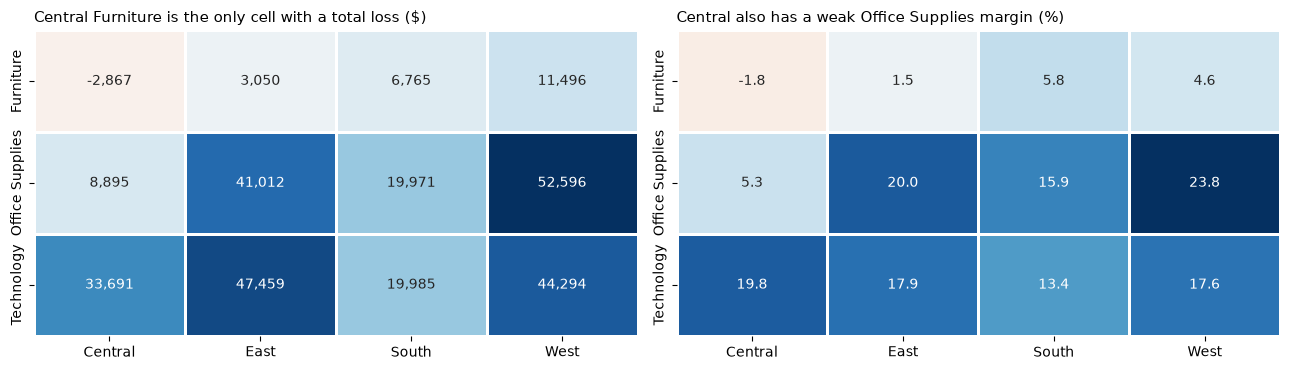

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sb.heatmap(profit_table, annot=True, fmt=",.0f", cmap="RdBu", center=0, linewidths=2, linecolor="white",
           cbar=False, ax=ax[0])
ax[0].set_title("Central Furniture is the only cell with a total loss ($)", loc="left", fontsize=11)
sb.heatmap(margin_region, annot=True, fmt=".1f", cmap="RdBu", center=0, linewidths=2, linecolor="white",
           cbar=False, ax=ax[1])
ax[1].set_title("Central also has a weak Office Supplies margin (%)", loc="left", fontsize=11)
for axis in ax:
    axis.set_xlabel("")
    axis.set_ylabel("")
plt.tight_layout()
plt.show()

In [7]:
print(pd.crosstab(df["Region"], df["Category"], normalize="index").round(3) * 100)

counts = pd.crosstab(df["Region"], df["Category"])
chi2, p, dof, expected = chi2_contingency(counts)
cramers_v = (chi2 / (counts.sum().sum() * (min(counts.shape) - 1))) ** 0.5
print(f"\nchi2 = {chi2:.2f}, p-value = {p:.4f}, dof = {dof}, Cramér's V = {cramers_v:.3f}")

Category  Furniture  Office Supplies  Technology
Region                                          
Central        20.7             61.2        18.1
East           21.1             60.1        18.8
South          20.5             61.4        18.1
West           22.1             59.2        18.7

chi2 = 3.66, p-value = 0.7223, dof = 6, Cramér's V = 0.014


**What we observe.**
- Central Furniture is the only negative cell out of 12: -$2,867, a margin of -1.8%.
- Central Office Supplies stays positive but earns 5.3%, against 20.0% in the East and 23.8% in the West.
- Technology is profitable everywhere, between 13.4% and 19.8%. Its best margin is in Central.
- The product mix is almost identical across regions, about 21% Furniture, 60% Office Supplies and 19% Technology. With p = 0.72 we cannot reject independence, and Cramér's V is close to 0.

**What we conclude.** Central's weakness is not spread over all its products. It sits in two categories out of three, and it does not come from selling more Furniture, because Central's mix is the same as everywhere else. Something else differs in those two cells.

**What the three variables add.** Region and Profit alone (Part II) only say that Central is the weakest. Category and Profit alone say that Furniture is the weakest. Crossed together, they show that Central's Technology margin is actually the highest of the four regions, so "Central is bad" is too general.

## Combination 2: Category × Region × Discount

**What we analyze.** Part II found a strong negative association between discount and profit ratio, so discounts are the obvious candidate for what differs in Central's two weak cells. We replace Profit with Discount in the same grid.

**How.** We use a pivot table of the mean discount, shown as a heatmap with a one-hue scale because a discount has no sign. The mean counts each line once, so a second table weights the discount by sales to check that small lines do not drive the result.

In [8]:
discount_table = df.pivot_table(values="Discount", index="Category", columns="Region", aggfunc="mean") * 100

df["Discount x Sales"] = df["Discount"] * df["Sales"]
weighted_discount = (df.pivot_table(values="Discount x Sales", index="Category", columns="Region", aggfunc="sum")
                     / df.pivot_table(values="Sales", index="Category", columns="Region", aggfunc="sum") * 100)

print("Mean discount per line (%):")
display(discount_table.round(1))
print("Sales-weighted discount (%):")
display(weighted_discount.round(1))

Mean discount per line (%):


Region,Central,East,South,West
Category,,,,
Furniture,29.7,15.4,12.2,13.1
Office Supplies,25.3,14.3,16.7,9.3
Technology,13.3,14.3,10.8,13.4


Sales-weighted discount (%):


Region,Central,East,South,West
Category,,,,
Furniture,18.5,18.5,12.7,15.8
Office Supplies,14.1,10.3,11.9,7.6
Technology,14.1,13.1,18.1,14.6


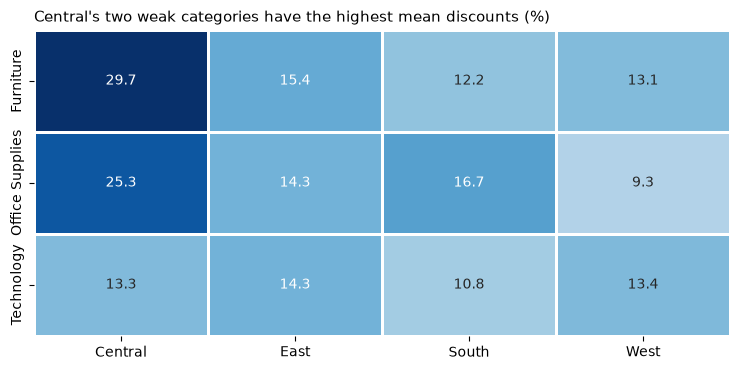

In [9]:
plt.figure(figsize=(7.5, 3.8))
sb.heatmap(discount_table, annot=True, fmt=".1f", cmap="Blues", vmin=0, linewidths=2, linecolor="white", cbar=False)
plt.title("Central's two weak categories have the highest mean discounts (%)", loc="left", fontsize=11)
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

**What we observe.**
- Central has the highest mean discount per line on Furniture (29.7%) and Office Supplies (25.3%). The other regions range from 9.3% to 16.7% on these two categories.
- On Technology, the one category where Central is healthy, its mean discount (13.3%) is in line with the others (10.8% to 14.3%).
- Weighting by sales narrows the gap. Central Furniture falls to 18.5%, the same as the East, and the East's Furniture margin is also very thin at 1.5%. So part of Central's high mean comes from many small discounted lines.

**What we conclude.** The cells with weak profit in Combination 1 are the cells with heavy discounting. This is an association: the table does not prove that discounts caused the weak margins, because a third factor could drive both. Combination 5 shows that it also hides a split inside Central.

**What the three variables add.** Region and Discount alone would average Central's high discounts with its normal Technology discounts. The grid shows that the high discounts and the weak margins fall in the same two cells, and that Technology, with normal discounts, stays healthy.

## Combination 3: Sales × Profit × Category

**What we analyze.** Two numerical variables and one categorical variable. We ask whether larger sales bring larger profit, and whether that holds in every category.

**How.** We compute Pearson's r with its p-value, as in Part II, and add Spearman's rho because Pearson is sensitive to a few extreme lines. The aggregate margin and the share of lines sold at a loss complete the table. For the chart we use one scatter panel per category with shared axes, so the categories can be compared without their points hiding each other.

In [10]:
rows = []
for category in ["Furniture", "Office Supplies", "Technology"]:
    subset = df[df["Category"] == category]
    r, p_r = pearsonr(subset["Sales"], subset["Profit"])
    rho, p_rho = spearmanr(subset["Sales"], subset["Profit"])
    rows.append({
        "Category": category,
        "Lines": len(subset),
        "Total sales": subset["Sales"].sum(),
        "Total profit": subset["Profit"].sum(),
        "Margin %": round(subset["Profit"].sum() / subset["Sales"].sum() * 100, 1),
        "Pearson r": round(r, 2),
        "p-value": p_r,
        "Spearman rho": round(rho, 2),
        "Loss lines %": round((subset["Profit"] < 0).mean() * 100, 1),
        "Min profit": subset["Profit"].min(),
        "Max profit": subset["Profit"].max(),
    })
category_summary = pd.DataFrame(rows).set_index("Category")
category_summary

,Lines,Total sales,Total profit,Margin %,Pearson r,p-value,Spearman rho,Loss lines %,Min profit,Max profit
Category,,,,,,,,,,
Furniture,2121,742006,18444,2.5,0.17,8.420257e-16,0.19,33.6,-1862,1013
Office Supplies,6026,719127,122474,17.0,0.55,0.000000e+00,0.69,14.7,-3702,4946
Technology,1847,836221,145429,17.4,0.51,2.993777e-120,0.68,14.5,-6600,8400


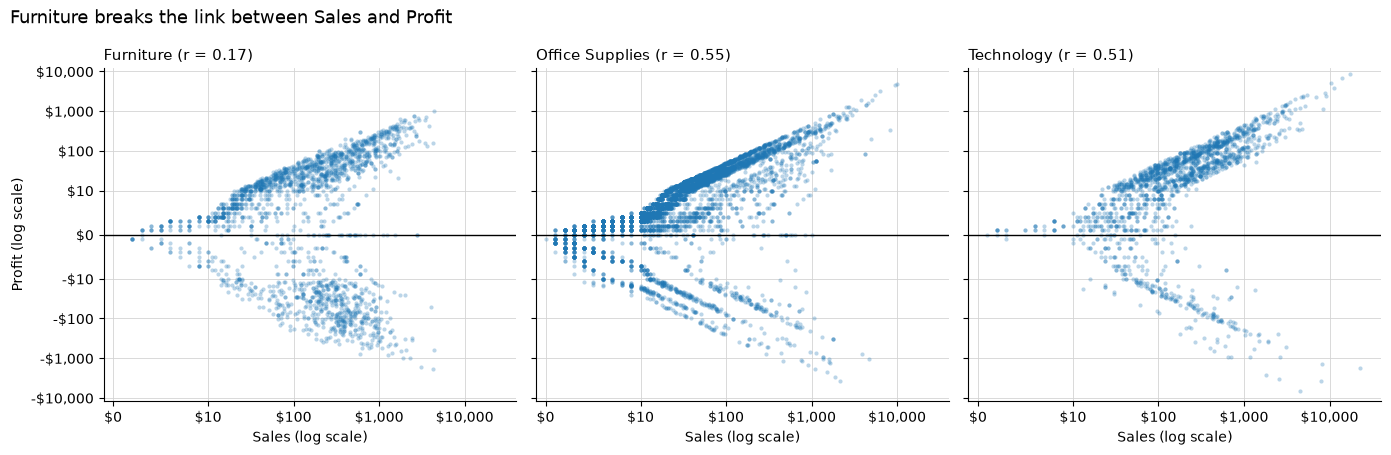

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for i, category in enumerate(["Furniture", "Office Supplies", "Technology"]):
    subset = df[df["Category"] == category]
    r = subset["Sales"].corr(subset["Profit"])
    plot_scatter_panel(ax[i], subset, f"{category} (r = {r:.2f})")
ax[0].set_ylabel("Profit (log scale)")
fig.suptitle("Furniture breaks the link between Sales and Profit", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

**What we observe.**
- All three correlations are significant, but Furniture's is weak (r = 0.17, rho = 0.19). Office Supplies (r = 0.55) and Technology (r = 0.51) are moderate. Spearman raises those two to 0.69 and 0.68, so the link is not caused by a few extreme lines.
- Furniture earns $742,006 in sales, more than Office Supplies, but only $18,444 in profit. Its margin is 2.5%, against about 17% for the other two.
- One Furniture line in three is sold at a loss (33.6%), more than twice the rate of the others.
- Technology has both the largest profit ($8,400) and the largest loss (-$6,600), so its range is the widest.

**What we conclude.** Higher sales go with higher profit in Office Supplies and Technology, but barely in Furniture. A large Furniture sale says almost nothing about whether it was profitable. This is an association between recorded sale size and profit: it does not show that selling more would raise profit.

**What the three variables add.** The overall Sales-Profit correlation is 0.48. That single number hides a clear difference between categories. The panels also show two bands in every category, one above zero and one below it, and the lower band is largest in Furniture. This suggests that one more variable separates them. Combination 4 tests this.

## Combination 4: Sales × Profit × Discount

**What we analyze.** Three numerical variables. We ask whether the Sales-Profit link stays the same when discounts are taken into account.

**How.** We start with the correlation matrix, in Pearson and Spearman versions. Discount has only 12 distinct values, most lines sit at 0% or 20%, so we then split the lines into the three discount levels and compute the statistics within each level. The chart is one panel per level with shared axes, which keeps the three numerical variables visible together.

In [12]:
print("Pearson:")
display(df[["Sales", "Profit", "Discount"]].corr(method="pearson").round(2))
print("Spearman:")
display(df[["Sales", "Profit", "Discount"]].corr(method="spearman").round(2))

Pearson:


,Sales,Profit,Discount
Sales,1.00,0.48,-0.03
Profit,0.48,1.00,-0.22
Discount,-0.03,-0.22,1.00


Spearman:


,Sales,Profit,Discount
Sales,1.00,0.52,-0.06
Profit,0.52,1.00,-0.54
Discount,-0.06,-0.54,1.00


In [13]:
rows = []
for level in levels:
    subset = df[df["Discount Level"] == level]
    rows.append({
        "Discount Level": level,
        "Lines": len(subset),
        "Pearson r": round(subset["Sales"].corr(subset["Profit"]), 2),
        "Spearman rho": round(subset["Sales"].corr(subset["Profit"], method="spearman"), 2),
        "Mean profit": round(subset["Profit"].mean(), 1),
        "Total profit": subset["Profit"].sum(),
        "Margin %": round(subset["Profit"].sum() / subset["Sales"].sum() * 100, 1),
        "Loss lines %": round((subset["Profit"] < 0).mean() * 100, 1),
    })
level_summary = pd.DataFrame(rows).set_index("Discount Level")
level_summary

,Lines,Pearson r,Spearman rho,Mean profit,Total profit,Margin %,Loss lines %
Discount Level,,,,,,,
No discount,4798,0.92,0.89,66.9,320946,29.5,0.0
Low (1-20%),3803,0.68,0.53,26.5,100785,11.9,13.6
High (>20%),1393,-0.49,-0.72,-97.2,-135384,-37.3,96.8


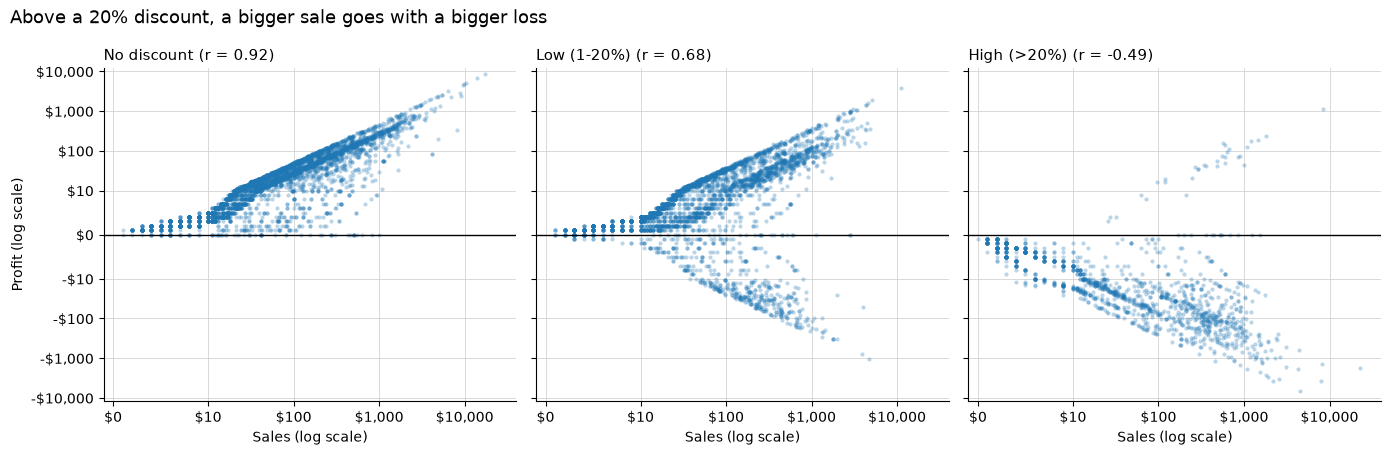

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for i, level in enumerate(levels):
    subset = df[df["Discount Level"] == level]
    r = subset["Sales"].corr(subset["Profit"])
    plot_scatter_panel(ax[i], subset, f"{level} (r = {r:.2f})")
ax[0].set_ylabel("Profit (log scale)")
fig.suptitle("Above a 20% discount, a bigger sale goes with a bigger loss", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

Combination 3 left a question open: is Furniture's weak correlation a property of Furniture, or of how it is discounted? We repeat the correlation and the margin inside each Category and Discount Level.

In [15]:
correlation_rows = {}
for category in ["Furniture", "Office Supplies", "Technology"]:
    correlation_rows[category] = {}
    for level in levels:
        subset = df[(df["Category"] == category) & (df["Discount Level"] == level)]
        correlation_rows[category][level] = round(subset["Sales"].corr(subset["Profit"]), 2)

print("Pearson r (Sales, Profit) within Category and Discount Level:")
display(pd.DataFrame(correlation_rows).T)

print("Margin (%) within Category and Discount Level:")
display(margin_table("Category", "Discount Level")[levels].round(1))

print("Share of the category's lines at each Discount Level (%):")
display((pd.crosstab(df["Category"], df["Discount Level"], normalize="index")[levels] * 100).round(1))

Pearson r (Sales, Profit) within Category and Discount Level:


,No discount,Low (1-20%),High (>20%)
Furniture,0.93,0.50,-0.69
Office Supplies,0.85,0.60,-0.92
Technology,0.97,0.85,-0.43


Margin (%) within Category and Discount Level:


Discount Level,No discount,Low (1-20%),High (>20%)
Category,,,
Furniture,22.7,5.1,-27.9
Office Supplies,29.5,16.5,-119.3
Technology,34.0,14.7,-26.3


Share of the category's lines at each Discount Level (%):


Discount Level,No discount,Low (1-20%),High (>20%)
Category,,,
Furniture,39.4,35.0,25.6
Office Supplies,51.9,36.8,11.3
Technology,45.1,45.6,9.3


In [16]:
high = df[df["Discount Level"] == "High (>20%)"]
high_table = high.pivot_table(values="Profit", index="Category", columns="Region", aggfunc="sum",
                              margins=True, margins_name="Total")
print("Total profit ($) of high-discount lines only:")
display(high_table)

losses = df[df["Profit"] < 0]["Profit"]
print(f"High-discount lines: {len(high) / len(df) * 100:.1f}% of all lines")
print(f"Share of all line-level losses from high-discount lines: "
      f"{high[high['Profit'] < 0]['Profit'].sum() / losses.sum() * 100:.1f}%")
print(f"Central Furniture + Office Supplies share of the high-discount total: "
      f"{(high_table.loc['Furniture', 'Central'] + high_table.loc['Office Supplies', 'Central']) / high_table.loc['Total', 'Total'] * 100:.1f}%")

Total profit ($) of high-discount lines only:


Region,Central,East,South,West,Total
Category,,,,,
Furniture,-19506,-17921,-8840,-8204,-54471
Office Supplies,-30546,-5977,-8411,-2225,-47159
Technology,-2340,-18190,-7635,-5589,-33754
Total,-52392,-42088,-24886,-16018,-135384


High-discount lines: 13.9% of all lines
Share of all line-level losses from high-discount lines: 88.7%
Central Furniture + Office Supplies share of the high-discount total: 37.0%


**What we observe.**
- In the full data, Discount looks only weakly related to Profit (r = -0.22) and unrelated to Sales (r = -0.03). Spearman gives -0.54 for Discount and Profit. Part II found -0.86 with Profit Ratio, because a ratio removes the size of the sale.
- Inside each level the picture changes completely. The Sales-Profit correlation goes from 0.92 with no discount, to 0.68 with a low discount, to -0.49 above 20% (rho = -0.72). The direction reverses.
- None of the 4,798 undiscounted lines is sold at a loss. Above 20%, 96.8% of lines are, for a total of -$135,384.
- High-discount lines are 13.9% of all lines but 88.7% of all line-level losses.
- Within a discount level, Furniture behaves like the others: r = 0.93 without a discount, close to Technology (0.97). Its overall 0.17 appears because very different groups are pooled together, since 25.6% of its lines are in the high level, against 11.3% for Office Supplies and 9.3% for Technology.
- Furniture still has the lowest undiscounted margin (22.7%, against 29.5% and 34.0%), so discounts are not the only reason for its 2.5% margin. It starts lower, and it is discounted more often.
- High-discount losses are not only a Central Furniture story. Central's Furniture and Office Supplies lines represent 37.0% of the high-discount total. The largest single cell is Central Office Supplies (-$30,546), and East Technology (-$18,190) and East Furniture (-$17,921) are close to Central Furniture (-$19,506).

**What we conclude.** The relationship between sales and profit depends on the discount level. At high discounts, a bigger sale goes with a bigger loss, which is expected if each line loses a similar share of its value. Most of the company's losses are in this small group of lines. We cannot conclude that removing these discounts would recover the $135,384: without the discount, some of these sales might not happen at all.

**What the three variables add.** This is the clearest gain of the analysis. Each pair is misleading on its own: Sales-Profit (r = 0.48) suggests that selling more is always good, and Discount-Sales (r = -0.03) suggests that discounts do not matter. Only the three together show the sign of the Sales-Profit relationship reversing. The extra split by Category also changes the Combination 3 reading, because most of Furniture's "weak link" disappears within a level.

## Combination 5: State × Discount × Profit

**What we analyze.** Everything so far has used Region. But a regional mean can hide very different states, so we ask whether high discounts and losses are spread over a region, or sit in specific states.

**How.** For each of the 49 states, we compute the total profit, the margin, the mean discount and the share of lines with no discount. The chart is a scatter plot with one point per state: mean discount on the x-axis, margin on the y-axis, and point size for sales. Central is highlighted because it is the region under investigation. We then split Central into Texas + Illinois and its 11 other states.

In [17]:
state_table = df.groupby(["State", "Region"]).agg(
    Lines=("Sales", "size"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Mean_discount=("Discount", "mean"),
    Lowest_discount=("Discount", "min"),
).reset_index()
state_table["Margin"] = state_table["Profit"] / state_table["Sales"] * 100
state_table["Mean_discount"] = state_table["Mean_discount"] * 100

loss_states = state_table[state_table["Profit"] < 0].sort_values("Profit")
other_states = state_table[state_table["Profit"] >= 0]
display(loss_states.round(1))

print(f"{len(loss_states)} loss-making states: {loss_states['Lines'].sum()} lines, ${loss_states['Profit'].sum():,} profit")
print(f"{len(other_states)} other states: {other_states['Lines'].sum()} lines, ${other_states['Profit'].sum():,} profit")
print(f"Highest mean discount among other states with more than one line: "
      f"{other_states[other_states['Lines'] > 1]['Mean_discount'].max():.1f}%")
print(f"r(mean discount, margin) across states = {state_table['Mean_discount'].corr(state_table['Margin']):.2f}")

,State,Region,Lines,Sales,Profit,Mean_discount,Lowest_discount,Margin
41,Texas,Central,985,170187,-25714,37.0,0.2,-15.1
33,Ohio,East,469,78253,-16962,32.5,0.2,-21.7
36,Pennsylvania,East,587,116522,-15550,32.9,0.2,-13.3
11,Illinois,Central,492,80162,-12607,39.0,0.2,-15.7
31,North Carolina,South,249,55604,-7495,28.4,0.2,-13.5
4,Colorado,West,182,32110,-6527,31.6,0.2,-20.3
40,Tennessee,South,183,30662,-5347,29.1,0.2,-17.4
1,Arizona,West,224,35283,-3432,30.4,0.2,-9.7
8,Florida,South,383,89479,-3412,29.9,0.2,-3.8
35,Oregon,West,124,17431,-1187,28.9,0.2,-6.8


10 loss-making states: 3878 lines, $-98,233 profit
39 other states: 6116 lines, $384,580 profit
Highest mean discount among other states with more than one line: 8.6%
r(mean discount, margin) across states = -0.96


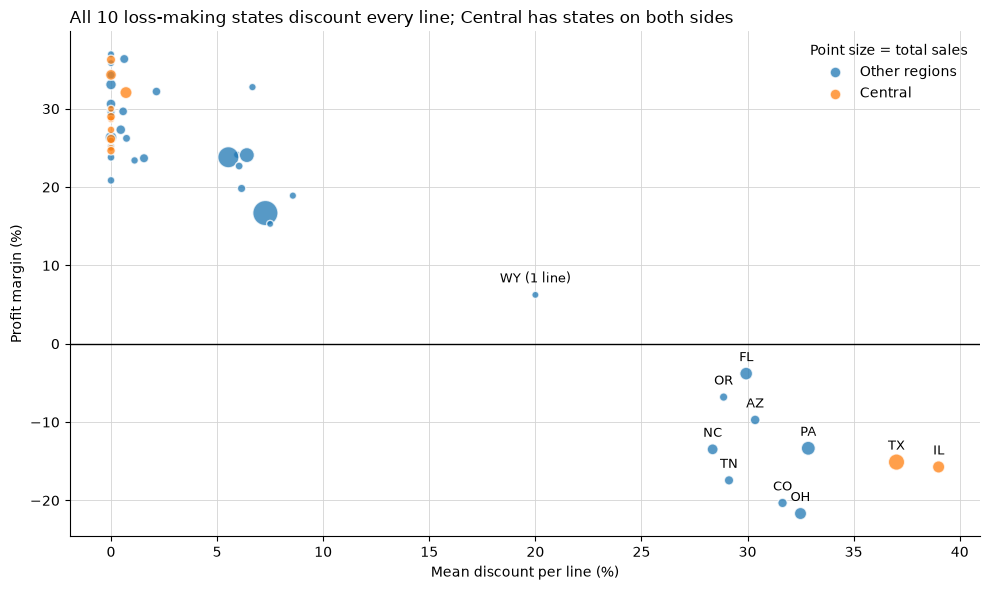

In [18]:
labels = {"Texas": "TX", "Illinois": "IL", "Pennsylvania": "PA", "Ohio": "OH", "Florida": "FL",
          "North Carolina": "NC", "Tennessee": "TN", "Arizona": "AZ", "Colorado": "CO", "Oregon": "OR",
          "Wyoming": "WY (1 line)"}

fig, axis = plt.subplots(figsize=(10, 6))
for in_central, color, name in [(False, "tab:blue", "Other regions"), (True, "tab:orange", "Central")]:
    subset = state_table[(state_table["Region"] == "Central") == in_central]
    axis.scatter(subset["Mean_discount"], subset["Margin"], s=subset["Sales"] / 1500 + 25, color=color,
                 alpha=0.75, edgecolor="white", linewidth=1, label=name)
for _, row in state_table[state_table["State"].isin(labels)].iterrows():
    axis.annotate(labels[row["State"]], (row["Mean_discount"], row["Margin"]), xytext=(0, 9),
                  textcoords="offset points", ha="center", fontsize=9)
axis.axhline(0, color="black", linewidth=1)
axis.set_title("All 10 loss-making states discount every line; Central has states on both sides", loc="left", fontsize=12)
axis.set_xlabel("Mean discount per line (%)")
axis.set_ylabel("Profit margin (%)")
axis.grid(color="lightgray", linewidth=0.6)
axis.set_axisbelow(True)
axis.spines[["top", "right"]].set_visible(False)
legend = axis.legend(title="Point size = total sales", frameon=False, loc="upper right")
for handle in legend.legend_handles:
    handle.set_sizes([60])
plt.tight_layout()
plt.show()

In [19]:
central = df[df["Region"] == "Central"].copy()
central["Group"] = central["State"].apply(lambda state: "Texas + Illinois" if state in ["Texas", "Illinois"]
                                          else "11 other states")

central_summary = central.groupby("Group").agg(
    Lines=("Sales", "size"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Mean_discount=("Discount", "mean"),
)
central_summary["Mean_discount"] = (central_summary["Mean_discount"] * 100).round(1)
central_summary["Margin %"] = (central_summary["Profit"] / central_summary["Sales"] * 100).round(1)
display(central_summary)

print("Central profit ($) by Category and Group:")
display(central.pivot_table(values="Profit", index="Category", columns="Group", aggfunc="sum"))

,Lines,Sales,Profit,Mean_discount,Margin %
Group,,,,,
11 other states,846,250907,78040,0.2,31.1
Texas + Illinois,1477,250349,-38321,37.7,-15.3


Central profit ($) by Category and Group:


Group,11 other states,Texas + Illinois
Category,,
Furniture,16639,-19506
Office Supplies,35823,-26928
Technology,25578,8113


In [20]:
texas_illinois = central[central["Group"] == "Texas + Illinois"]
print("Texas + Illinois: number of lines at each discount rate, per Sub-Category")
pd.crosstab(texas_illinois["Sub-Category"], texas_illinois["Discount"])

Texas + Illinois: number of lines at each discount rate, per Sub-Category


Discount,0.20,0.30,0.32,0.40,0.50,0.60,0.80
Sub-Category,,,,,,,
Accessories,114,0,0,0,0,0,0
Appliances,0,0,0,0,0,0,67
Art,108,0,0,0,0,0,0
Binders,0,0,0,0,0,0,233
Bookcases,0,10,27,0,0,0,0
Chairs,0,99,0,0,0,0,0
Copiers,9,0,0,0,0,0,0
Envelopes,38,0,0,0,0,0,0
Fasteners,37,0,0,0,0,0,0


**What we observe.**
- Exactly 10 of the 49 states lose money: Texas, Ohio, Pennsylvania, Illinois, North Carolina, Colorado, Tennessee, Arizona, Florida and Oregon. Together they total -$98,233, while the other 39 states earn +$384,580.
- In all 10, the lowest discount is 20%: not one line is sold without a discount. Among the other states with more than one line, the mean discount never exceeds 8.6%, while the loss-making states are all at 28.4% or above. Only Wyoming falls in between, with a single line in the whole dataset. Across states, r(mean discount, margin) = -0.96.
- These states are in all four regions: two in Central, two in the East, three in the South and three in the West. Part II's regional ranking partly reflects how much each region's sales fall in these states.
- Central is two different businesses of almost equal size. Texas + Illinois sell $250,349 with a 37.7% mean discount and a -15.3% margin. Its 11 other states sell $250,907 with a 0.2% mean discount and a +31.1% margin.
- Central Furniture's -$2,867 is the sum of -$19,506 in Texas + Illinois and +$16,639 elsewhere.
- In Texas and Illinois, the discount is close to a fixed rate by sub-category: all 233 Binders lines are at 80%, all 67 Appliances lines at 80%, all 138 Furnishings lines at 60%, and all 99 Chairs lines at 30%.

**What we conclude.** The discount pattern looks like a state-level pricing rule rather than a Central Region behaviour, because it starts and stops at state borders. The loss is a problem of 10 states and not of one region.

The evidence for causation is still limited. Every line in these states is discounted, so we cannot compare discounted and undiscounted sales inside the same state, and the states may differ in other ways, such as competition or costs. The data show a very strong association. To measure the actual effect of the discounts, the company would need to change them in some states or products and compare the results.

**What the three variables add.** Region × Profit (Part II) named Central. Adding Category named Furniture. Adding State, Discount and Profit together shows that these labels were partly averages: most of Central earns a 31.1% margin, and comparable losses appear in the East, South and West.

## Overall findings

1. **Losses follow discounts more closely than products or regions.** The mix of categories does not differ by region (Combination 1), while weak cells and high discounts coincide (Combination 2).
2. **The Sales-Profit relationship depends on the discount.** It goes from r = 0.92 with no discount to -0.49 above 20%, and none of the undiscounted lines lost money (Combination 4).
3. **A small group of lines accounts for most of the losses.** High-discount lines are 13.9% of lines but 88.7% of line-level losses, for a net -$135,384 (Combination 4).
4. **Furniture has two separate problems.** Its undiscounted margin is the lowest of the three categories, and a quarter of its lines are heavily discounted (Combinations 3 and 4).
5. **The right level is the state, not the region.** All 10 loss-making states discount every line, and they are spread over all four regions. Central's two halves earn -15.3% and +31.1% (Combination 5).

**Main insight for the company.** The first place to look is the discount rule used in these 10 states, especially the highest rates on Binders, Appliances, Furnishings and Tables. Because these results are observational, the next step would be a controlled price test, not an immediate conclusion that lower discounts would restore the profit.

### Reproducibility check

The text above quotes fixed numbers from this dataset. This cell recomputes the main ones, so a change in the data or the code stops the notebook here instead of leaving an outdated interpretation.

In [21]:
assert df.shape[0] == 9994 and df["Profit"].sum() == 286347
assert profit_table.loc["Furniture", "Central"] == -2867
assert (profit_table < 0).sum().sum() == 1
assert round(margin_region.loc["Office Supplies", "West"], 1) == 23.8
assert level_summary.loc["No discount", "Loss lines %"] == 0
assert level_summary.loc["High (>20%)", "Total profit"] == -135384
assert len(loss_states) == 10 and loss_states["Profit"].sum() == -98233
assert (loss_states["Lowest_discount"] >= 0.20).all()
assert other_states["Profit"].sum() == 384580
assert central_summary.loc["Texas + Illinois", "Margin %"] == -15.3
assert central_summary.loc["11 other states", "Margin %"] == 31.1
print("All quoted figures match the data.")

All quoted figures match the data.
